# Implémentation de LeNet-5 sur la base AMHCD RGB

**Objectif :** implémenter et entraîner un réseau de neurones convolutif LeNet-5 pour la reconnaissance des caractères manuscrits amazighs de la base AMHCD.

Le travail comprend :
- La préparation et la visualisation des images RGB.
- L'implémentation paramétrable de LeNet-5.
- L'entraînement et la validation du modèle.
- La comparaison des optimiseurs SGD et Adam.
- L'évaluation quantitative et qualitative sur le jeu de test.
- La visualisation des courbes d'apprentissage, de la matrice de confusion et des cartes de caractéristiques.

In [ ]:

import os
import random
import time
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("PyTorch :", torch.__version__)
print("GPU disponible :", torch.cuda.is_available())

PyTorch : 2.11.0+cpu
GPU disponible : False


In [ ]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 32
BATCH_SIZE = 64
EPOCHS = 20
LEARNING_RATE = 0.001

print("Appareil utilisé :", DEVICE)

Appareil utilisé : cpu


In [ ]:

!pip -q install kagglehub

import kagglehub

DATASET_PATH = kagglehub.dataset_download(
    "benaddym/amazigh-handwritten-character-database-amhcd"
)

print("Dataset téléchargé dans :", DATASET_PATH)

100%|██████████| 67.9M/67.9M [00:02<00:00, 24.6MB/s]

Extracting files...


Dataset téléchargé dans : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1


In [ ]:

root = Path(DATASET_PATH)

for path in list(root.rglob("*"))[:60]:
    print(path.relative_to(root))


AMHCD_64
amhcd_64
labels
AMHCD_64/AMHCD_64
amhcd_64/AMHCD_64
labels/labels
labels/labels/sorted-33-common-tifinagh.txt
labels/labels/33-common-latin-tifinagh.txt
amhcd_64/AMHCD_64/yadd
amhcd_64/AMHCD_64/yu
amhcd_64/AMHCD_64/yas
amhcd_64/AMHCD_64/yat
amhcd_64/AMHCD_64/yag
amhcd_64/AMHCD_64/yaj
amhcd_64/AMHCD_64/yan
amhcd_64/AMHCD_64/yatt
amhcd_64/AMHCD_64/yax
amhcd_64/AMHCD_64/yaq
amhcd_64/AMHCD_64/yae
amhcd_64/AMHCD_64/yab
amhcd_64/AMHCD_64/yey
amhcd_64/AMHCD_64/yass
amhcd_64/AMHCD_64/yakw
amhcd_64/AMHCD_64/yazz
amhcd_64/AMHCD_64/yahh
amhcd_64/AMHCD_64/yaf
amhcd_64/AMHCD_64/yarr
amhcd_64/AMHCD_64/yal
amhcd_64/AMHCD_64/yak
amhcd_64/AMHCD_64/yagw
amhcd_64/AMHCD_64/yaw
amhcd_64/AMHCD_64/yach
amhcd_64/AMHCD_64/ya
amhcd_64/AMHCD_64/yam
amhcd_64/AMHCD_64/yagh
amhcd_64/AMHCD_64/yi
amhcd_64/AMHCD_64/yaz
amhcd_64/AMHCD_64/yay
amhcd_64/AMHCD_64/yah
amhcd_64/AMHCD_64/yar
amhcd_64/AMHCD_64/yad
amhcd_64/AMHCD_64/yadd/yadd_50.jpeg
amhcd_64/AMHCD_64/yadd/yadd_649.jpeg
amhcd_64/AMHCD_64/yadd/yadd_670.

In [ ]:

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def count_images(folder):
    return sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

candidates = []

for folder in [root] + list(root.rglob("*")):
    if not folder.is_dir():
        continue

    subdirs = [d for d in folder.iterdir() if d.is_dir()]
    valid_classes = [
        d for d in subdirs if count_images(d) > 0
    ]

    if len(valid_classes) >= 2:
        candidates.append(
            (folder, len(valid_classes), count_images(folder))
        )

for folder, n_classes, n_images in sorted(
    candidates, key=lambda x: x[2], reverse=True
)[:10]:
    print(
        f"Dossier : {folder} | "
        f"Classes : {n_classes} | Images : {n_images}"
    )

Dossier : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1 | Classes : 2 | Images : 51480
Dossier : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1/AMHCD_64/AMHCD_64 | Classes : 33 | Images : 25740
Dossier : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1/amhcd_64/AMHCD_64 | Classes : 33 | Images : 25740


In [ ]:


from pathlib import Path
from torchvision import datasets

DATA_DIR = Path(DATASET_PATH) / "AMHCD_64" / "AMHCD_64"

print("Dossier utilisé :", DATA_DIR)
print("Dossier existe :", DATA_DIR.exists())

dataset_check = datasets.ImageFolder(DATA_DIR)

print("Nombre d'images :", len(dataset_check))
print("Nombre de classes :", len(dataset_check.classes))
print("Classes :", dataset_check.classes)

Dossier utilisé : /root/.cache/kagglehub/datasets/benaddym/amazigh-handwritten-character-database-amhcd/versions/1/AMHCD_64/AMHCD_64
Dossier existe : True
Nombre d'images : 25740
Nombre de classes : 33
Classes : ['ya', 'yab', 'yach', 'yad', 'yadd', 'yae', 'yaf', 'yag', 'yagh', 'yagw', 'yah', 'yahh', 'yaj', 'yak', 'yakw', 'yal', 'yam', 'yan', 'yaq', 'yar', 'yarr', 'yas', 'yass', 'yat', 'yatt', 'yaw', 'yax', 'yay', 'yaz', 'yazz', 'yey', 'yi', 'yu']


In [ ]:

train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

eval_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5),
                         (0.5, 0.5, 0.5))
])

# Deux instances : augmentation pour train uniquement
train_dataset_full = datasets.ImageFolder(
    DATA_DIR, transform=train_transform
)
eval_dataset_full = datasets.ImageFolder(
    DATA_DIR, transform=eval_transform
)

targets = np.array(train_dataset_full.targets)
indices = np.arange(len(targets))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=targets[temp_idx]
)

train_dataset = Subset(train_dataset_full, train_idx)
val_dataset = Subset(eval_dataset_full, val_idx)
test_dataset = Subset(eval_dataset_full, test_idx)

print(f"Train : {len(train_dataset)} images")
print(f"Validation : {len(val_dataset)} images")
print(f"Test : {len(test_dataset)} images")
print(f"Classes : {len(train_dataset_full.classes)}")

Train : 18018 images
Validation : 3861 images
Test : 3861 images
Classes : 33


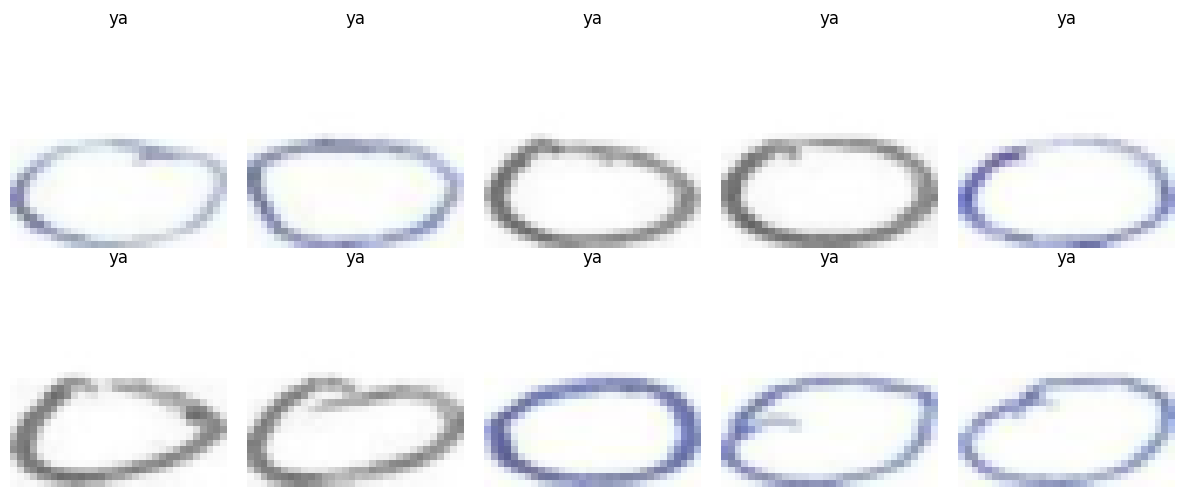

In [ ]:

def show_image(tensor, title=""):
    # Annuler la normalisation
    img = tensor.permute(1, 2, 0).cpu().numpy()
    img = img * 0.5 + 0.5
    img = np.clip(img, 0, 1)

    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, idx in zip(axes.flat, range(10)):
    image, label = eval_dataset_full[idx]
    plt.sca(ax)
    show_image(image, train_dataset_full.classes[label])

plt.tight_layout()
plt.show()

In [ ]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))
print("Dimension d'un batch :", images.shape)
print("Dimension des labels :", labels.shape)

Dimension d'un batch : torch.Size([64, 3, 32, 32])
Dimension des labels : torch.Size([64])


In [ ]:

class LeNet5(nn.Module):
    def __init__(
        self,
        num_classes,
        in_channels=3,
        activation="tanh",
        pool_type="avg"
    ):
        super().__init__()

        if activation == "tanh":
            act = nn.Tanh
        elif activation == "relu":
            act = nn.ReLU
        else:
            raise ValueError("Activation : tanh ou relu")

        if pool_type == "avg":
            pool = nn.AvgPool2d
        elif pool_type == "max":
            pool = nn.MaxPool2d
        else:
            raise ValueError("Pooling : avg ou max")

        self.conv1 = nn.Conv2d(
            in_channels, 6, kernel_size=5
        )
        self.act1 = act()
        self.pool1 = pool(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(
            6, 16, kernel_size=5
        )
        self.act2 = act()
        self.pool2 = pool(kernel_size=2, stride=2)

        # 32 -> 28 -> 14 -> 10 -> 5
        self.conv3 = nn.Conv2d(
            16, 120, kernel_size=5
        )
        self.act3 = act()

        self.fc1 = nn.Linear(120, 84)
        self.act4 = act()
        self.fc2 = nn.Linear(84, num_classes)

    def forward(self, x):
        x = self.pool1(self.act1(self.conv1(x)))
        x = self.pool2(self.act2(self.conv2(x)))
        x = self.act3(self.conv3(x))

        x = torch.flatten(x, start_dim=1)
        x = self.act4(self.fc1(x))
        x = self.fc2(x)

        return x

    def feature_maps(self, x):
        """Retourne les cartes de caractéristiques des convolutions."""
        c1 = self.act1(self.conv1(x))
        s2 = self.pool1(c1)

        c3 = self.act2(self.conv2(s2))
        s4 = self.pool2(c3)

        c5 = self.act3(self.conv3(s4))

        return {
            "C1": c1,
            "S2": s2,
            "C3": c3,
            "S4": s4,
            "C5": c5
        }


NUM_CLASSES = len(train_dataset_full.classes)

model = LeNet5(
    num_classes=NUM_CLASSES,
    in_channels=3,
    activation="tanh",
    pool_type="avg"
).to(DEVICE)

print(model)
print("Nombre de paramètres :", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

LeNet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (act1): Tanh()
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (act2): Tanh()
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (act3): Tanh()
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (act4): Tanh()
  (fc2): Linear(in_features=84, out_features=33, bias=True)
)
Nombre de paramètres : 63961


In [ ]:

x = torch.randn(1, 3, 32, 32).to(DEVICE)

with torch.no_grad():
    maps = model.feature_maps(x)

for name, feature in maps.items():
    print(name, ":", tuple(feature.shape))

with torch.no_grad():
    output = model(x)

print("Sortie finale :", tuple(output.shape))

C1 : (1, 6, 28, 28)
S2 : (1, 6, 14, 14)
C3 : (1, 16, 10, 10)
S4 : (1, 16, 5, 5)
C5 : (1, 120, 1, 1)
Sortie finale : (1, 33)


In [ ]:

def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate_loss_accuracy(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total

In [ ]:

def fit_model(model, train_loader, val_loader, optimizer,
              epochs=EPOCHS):

    criterion = nn.CrossEntropyLoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    start_time = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc = evaluate_loss_accuracy(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())

        print(
            f"Époque {epoch + 1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f}"
        )

    model.load_state_dict(best_weights)

    elapsed = time.time() - start_time
    print(f"Durée d'entraînement : {elapsed:.1f} secondes")

    return history, elapsed

In [ ]:

model_adam = LeNet5(
    num_classes=NUM_CLASSES,
    in_channels=3,
    activation="tanh",
    pool_type="avg"
).to(DEVICE)

optimizer_adam = optim.Adam(
    model_adam.parameters(),
    lr=LEARNING_RATE
)

history_adam, time_adam = fit_model(
    model_adam,
    train_loader,
    val_loader,
    optimizer_adam
)

torch.save(model_adam.state_dict(), "lenet5_amhcd_adam.pth")

Époque 01/20 | Train Loss: 1.6349 | Train Acc: 0.6002 | Val Loss: 0.6829 | Val Acc: 0.8399
Époque 02/20 | Train Loss: 0.5450 | Train Acc: 0.8684 | Val Loss: 0.3892 | Val Acc: 0.8948
Époque 03/20 | Train Loss: 0.3683 | Train Acc: 0.9074 | Val Loss: 0.2788 | Val Acc: 0.9236
Époque 04/20 | Train Loss: 0.2734 | Train Acc: 0.9287 | Val Loss: 0.2036 | Val Acc: 0.9438
Époque 05/20 | Train Loss: 0.2149 | Train Acc: 0.9451 | Val Loss: 0.2237 | Val Acc: 0.9371
Époque 06/20 | Train Loss: 0.1762 | Train Acc: 0.9527 | Val Loss: 0.1419 | Val Acc: 0.9573
Époque 07/20 | Train Loss: 0.1481 | Train Acc: 0.9604 | Val Loss: 0.1262 | Val Acc: 0.9640
Époque 08/20 | Train Loss: 0.1236 | Train Acc: 0.9678 | Val Loss: 0.1224 | Val Acc: 0.9661
Époque 09/20 | Train Loss: 0.1143 | Train Acc: 0.9686 | Val Loss: 0.1064 | Val Acc: 0.9681
Époque 10/20 | Train Loss: 0.0920 | Train Acc: 0.9759 | Val Loss: 0.0990 | Val Acc: 0.9694
Époque 11/20 | Train Loss: 0.0842 | Train Acc: 0.9784 | Val Loss: 0.0906 | Val Acc: 0.9728

In [ ]:

torch.manual_seed(SEED)

model_sgd = LeNet5(
    num_classes=NUM_CLASSES,
    in_channels=3,
    activation="tanh",
    pool_type="avg"
).to(DEVICE)

optimizer_sgd = optim.SGD(
    model_sgd.parameters(),
    lr=0.01,
    momentum=0.9
)

history_sgd, time_sgd = fit_model(
    model_sgd,
    train_loader,
    val_loader,
    optimizer_sgd
)

torch.save(model_sgd.state_dict(), "lenet5_amhcd_sgd.pth")

Époque 01/20 | Train Loss: 3.2657 | Train Acc: 0.1454 | Val Loss: 2.1899 | Val Acc: 0.4665
Époque 02/20 | Train Loss: 1.3068 | Train Acc: 0.6892 | Val Loss: 0.7897 | Val Acc: 0.8102
Époque 03/20 | Train Loss: 0.6284 | Train Acc: 0.8479 | Val Loss: 0.4476 | Val Acc: 0.8943
Époque 04/20 | Train Loss: 0.4200 | Train Acc: 0.8950 | Val Loss: 0.3809 | Val Acc: 0.9039
Époque 05/20 | Train Loss: 0.3110 | Train Acc: 0.9175 | Val Loss: 0.2297 | Val Acc: 0.9391
Époque 06/20 | Train Loss: 0.2522 | Train Acc: 0.9345 | Val Loss: 0.1825 | Val Acc: 0.9500
Époque 07/20 | Train Loss: 0.1990 | Train Acc: 0.9458 | Val Loss: 0.1879 | Val Acc: 0.9508
Époque 08/20 | Train Loss: 0.1748 | Train Acc: 0.9528 | Val Loss: 0.1424 | Val Acc: 0.9611
Époque 09/20 | Train Loss: 0.1449 | Train Acc: 0.9614 | Val Loss: 0.1273 | Val Acc: 0.9658
Époque 10/20 | Train Loss: 0.1287 | Train Acc: 0.9655 | Val Loss: 0.1122 | Val Acc: 0.9697
Époque 11/20 | Train Loss: 0.1134 | Train Acc: 0.9693 | Val Loss: 0.1123 | Val Acc: 0.9694

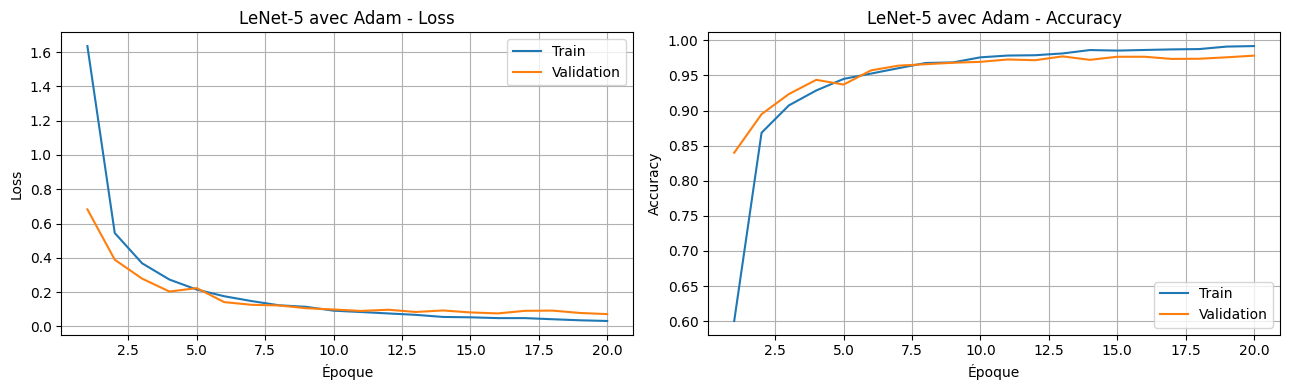

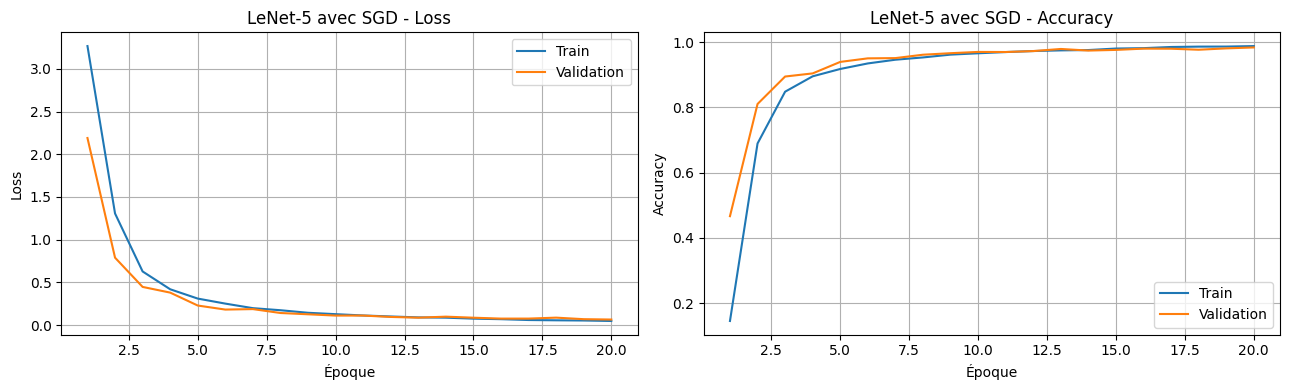

In [ ]:

def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, history["train_loss"], label="Train")
    axes[0].plot(epochs, history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Époque")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs, history["train_acc"], label="Train")
    axes[1].plot(epochs, history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Époque")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


plot_history(history_adam, "LeNet-5 avec Adam")
plot_history(history_sgd, "LeNet-5 avec SGD")

In [ ]:

@torch.no_grad()
def predict_model(model, loader):
    model.eval()

    all_labels = []
    all_predictions = []

    for images, labels in loader:
        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)


def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


y_true_adam, y_pred_adam = predict_model(model_adam, test_loader)
y_true_sgd, y_pred_sgd = predict_model(model_sgd, test_loader)

metrics_adam = calculate_metrics(y_true_adam, y_pred_adam)
metrics_sgd = calculate_metrics(y_true_sgd, y_pred_sgd)

print("Résultats Adam :", metrics_adam)
print("Résultats SGD  :", metrics_sgd)

Résultats Adam : {'Accuracy': 0.9738409738409738, 'Precision_macro': 0.9742709854208367, 'Recall_macro': 0.9738409738409738, 'F1_macro': 0.9738736788281942}
Résultats SGD  : {'Accuracy': 0.9795389795389795, 'Precision_macro': 0.9797768208731188, 'Recall_macro': 0.9795389795389795, 'F1_macro': 0.9795362017457351}


In [ ]:

results = pd.DataFrame(
    [
        {"Optimiseur": "Adam",
         **metrics_adam,
         "Durée (s)": time_adam},
        {"Optimiseur": "SGD",
         **metrics_sgd,
         "Durée (s)": time_sgd}
    ]
)

display(results.round(4))
results.to_csv("comparaison_optimiseurs.csv", index=False)

,Optimiseur,Accuracy,Precision_macro,Recall_macro,F1_macro,Durée (s)
0,Adam,0.9738,0.9743,0.9738,0.9739,383.9001
1,SGD,0.9795,0.9798,0.9795,0.9795,377.6589


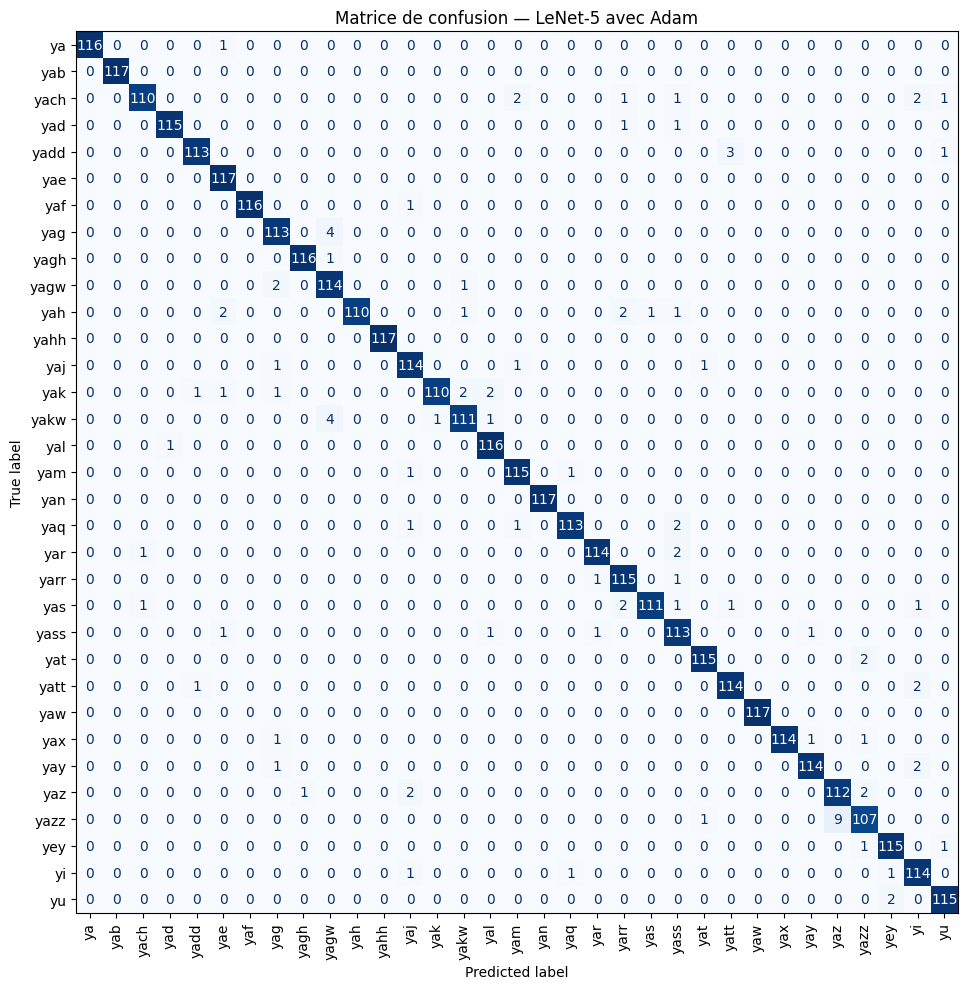

In [ ]:

class_names = eval_dataset_full.classes

cm = confusion_matrix(
    y_true_adam,
    y_pred_adam,
    labels=np.arange(NUM_CLASSES)
)

fig, ax = plt.subplots(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Matrice de confusion — LeNet-5 avec Adam")
plt.tight_layout()
plt.show()

In [ ]:

print(classification_report(
    y_true_adam,
    y_pred_adam,
    labels=np.arange(NUM_CLASSES),
    target_names=class_names,
    zero_division=0,
    digits=4
))

              precision    recall  f1-score   support

          ya     1.0000    0.9915    0.9957       117
         yab     1.0000    1.0000    1.0000       117
        yach     0.9821    0.9402    0.9607       117
         yad     0.9914    0.9829    0.9871       117
        yadd     0.9826    0.9658    0.9741       117
         yae     0.9590    1.0000    0.9791       117
         yaf     1.0000    0.9915    0.9957       117
         yag     0.9496    0.9658    0.9576       117
        yagh     0.9915    0.9915    0.9915       117
        yagw     0.9268    0.9744    0.9500       117
         yah     1.0000    0.9402    0.9692       117
        yahh     1.0000    1.0000    1.0000       117
         yaj     0.9500    0.9744    0.9620       117
         yak     0.9910    0.9402    0.9649       117
        yakw     0.9652    0.9487    0.9569       117
         yal     0.9667    0.9915    0.9789       117
         yam     0.9664    0.9829    0.9746       117
         yan     1.0000    

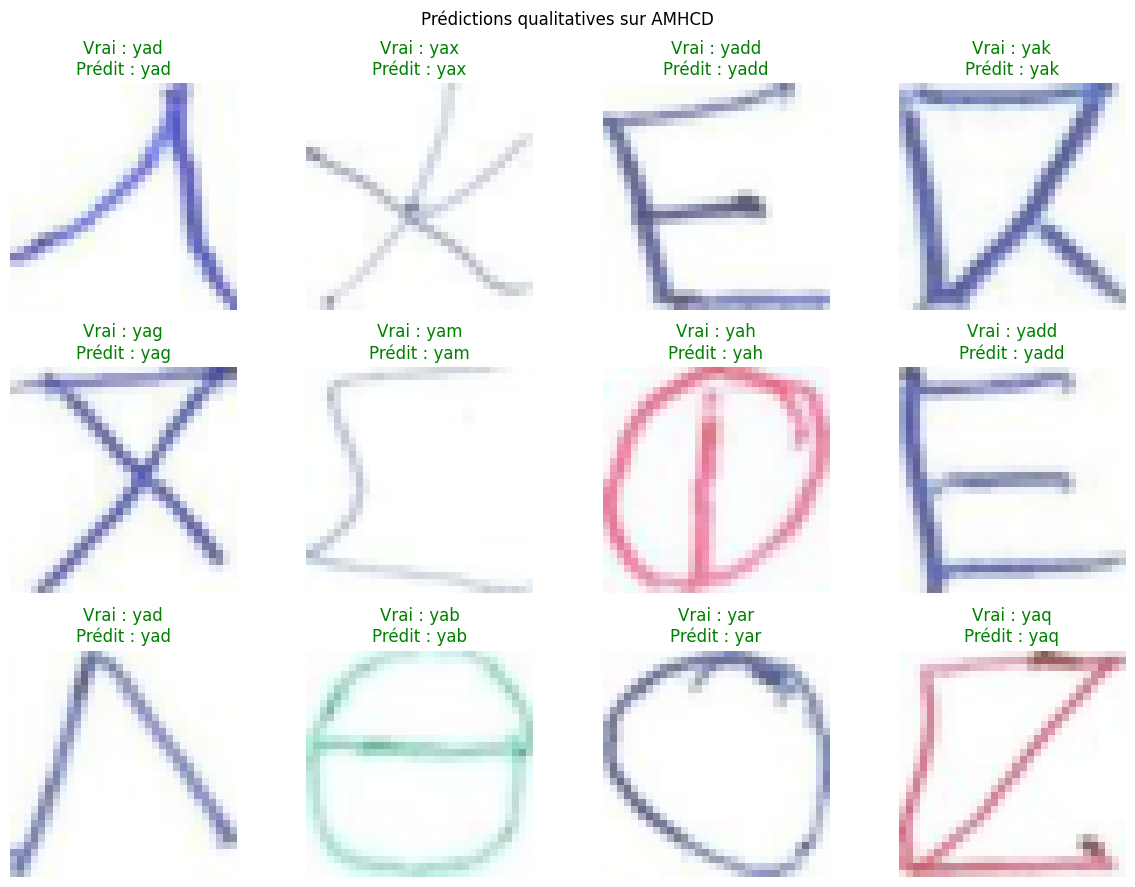

In [ ]:

def denormalize(image):
    image = image.permute(1, 2, 0).cpu().numpy()
    image = image * 0.5 + 0.5
    return np.clip(image, 0, 1)


model = model_adam
model.eval()

n_images = min(12, len(test_dataset))
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    if i >= n_images:
        ax.axis("off")
        continue

    image, label = test_dataset[i]

    with torch.no_grad():
        output = model(image.unsqueeze(0).to(DEVICE))
        pred = output.argmax(dim=1).item()

    true_name = class_names[label]
    pred_name = class_names[pred]

    ax.imshow(denormalize(image))
    ax.set_title(
        f"Vrai : {true_name}\nPrédit : {pred_name}",
        color="green" if label == pred else "red"
    )
    ax.axis("off")

plt.suptitle("Prédictions qualitatives sur AMHCD")
plt.tight_layout()
plt.show()

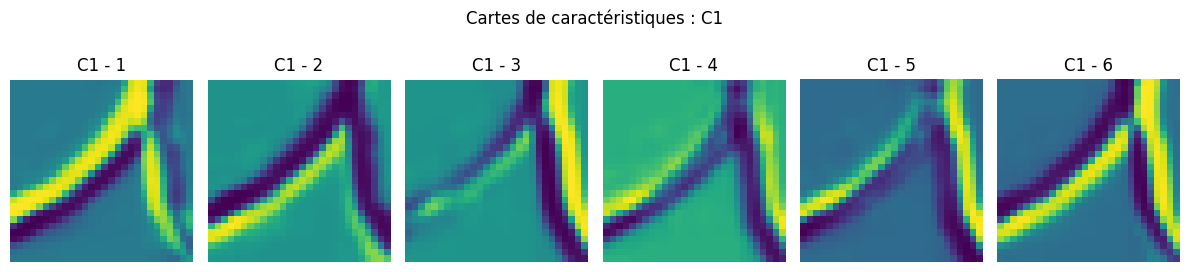

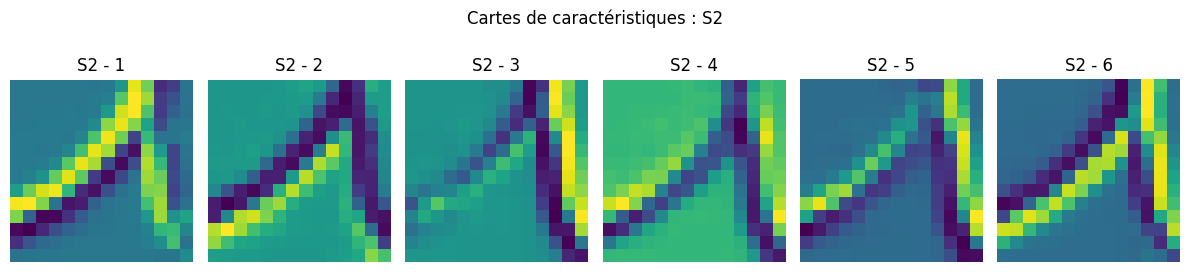

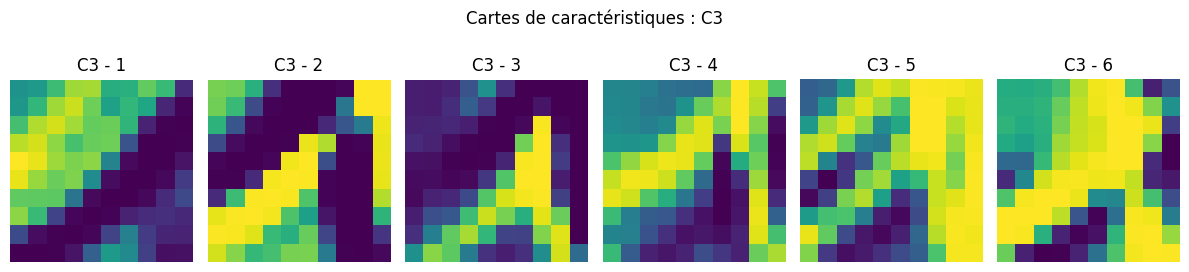

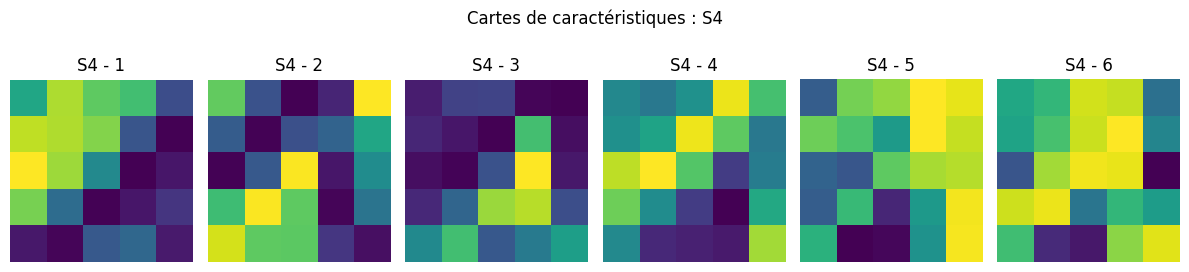

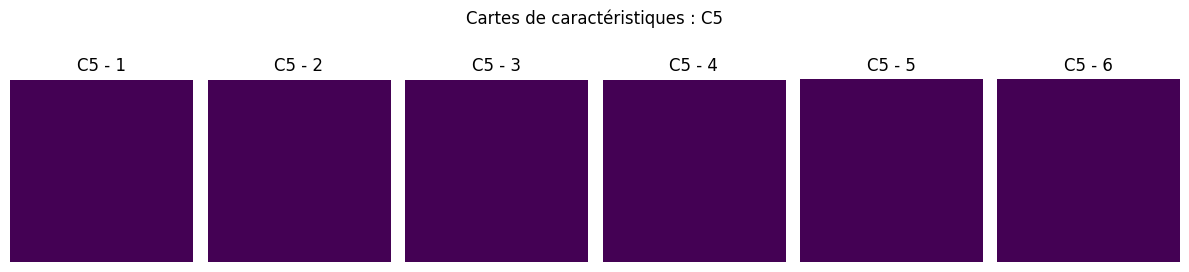

In [ ]:

image, label = test_dataset[0]
x = image.unsqueeze(0).to(DEVICE)

model = model_adam
model.eval()

with torch.no_grad():
    features = model.feature_maps(x)

for layer_name, feature in features.items():
    fmap = feature[0].cpu()

    n_maps = min(6, fmap.shape[0])
    fig, axes = plt.subplots(
        1, n_maps, figsize=(2 * n_maps, 3)
    )

    if n_maps == 1:
        axes = [axes]

    for i in range(n_maps):
        axes[i].imshow(fmap[i], cmap="viridis")
        axes[i].set_title(f"{layer_name} - {i + 1}")
        axes[i].axis("off")

    plt.suptitle(f"Cartes de caractéristiques : {layer_name}")
    plt.tight_layout()
    plt.show()

Nombre d'erreurs : 101
Nombre total de tests : 3861


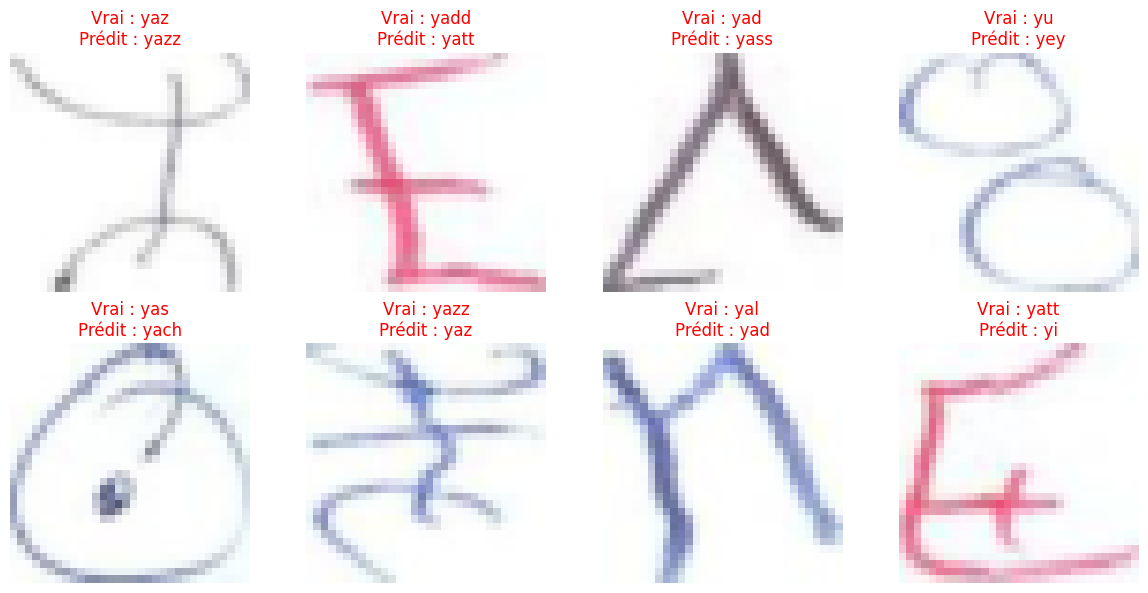

In [ ]:

wrong_indices = np.where(y_true_adam != y_pred_adam)[0]

print("Nombre d'erreurs :", len(wrong_indices))
print("Nombre total de tests :", len(y_true_adam))

if len(wrong_indices) > 0:
    n_show = min(8, len(wrong_indices))
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))

    for ax, idx in zip(axes.flat, wrong_indices[:n_show]):
        image, label = test_dataset[int(idx)]
        pred = int(y_pred_adam[idx])

        ax.imshow(denormalize(image))
        ax.set_title(
            f"Vrai : {class_names[label]}\n"
            f"Prédit : {class_names[pred]}",
            color="red"
        )
        ax.axis("off")

    for ax in axes.flat[n_show:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur sur cet échantillon de test.")

In [ ]:
torch.save(model_adam.state_dict(), "lenet5_amhcd_final.pth")

results.to_csv(
    "resultats_lenet5_amhcd.csv",
    index=False
)

print("Fichiers générés :")
print("- lenet5_amhcd_final.pth")
print("- lenet5_amhcd_adam.pth")
print("- lenet5_amhcd_sgd.pth")
print("- resultats_lenet5_amhcd.csv")
print("- comparaison_optimiseurs.csv")

Fichiers générés :
- lenet5_amhcd_final.pth
- lenet5_amhcd_adam.pth
- lenet5_amhcd_sgd.pth
- resultats_lenet5_amhcd.csv
- comparaison_optimiseurs.csv


In [ ]:

best_optimizer = results.loc[
    results["Accuracy"].idxmax(), "Optimiseur"
]

print("===== RÉSUMÉ DU TP =====")
print("Dataset : AMHCD")
print("Format des images : RGB")
print("Taille des images :", IMAGE_SIZE, "x", IMAGE_SIZE)
print("Nombre de classes :", NUM_CLASSES)
print("Images d'entraînement :", len(train_dataset))
print("Images de validation :", len(val_dataset))
print("Images de test :", len(test_dataset))
print("Optimiseur avec la meilleure accuracy test :", best_optimizer)

display(results.round(4))

===== RÉSUMÉ DU TP =====
Dataset : AMHCD
Format des images : RGB
Taille des images : 32 x 32
Nombre de classes : 33
Images d'entraînement : 18018
Images de validation : 3861
Images de test : 3861
Optimiseur avec la meilleure accuracy test : SGD


,Optimiseur,Accuracy,Precision_macro,Recall_macro,F1_macro,Durée (s)
0,Adam,0.9738,0.9743,0.9738,0.9739,383.9001
1,SGD,0.9795,0.9798,0.9795,0.9795,377.6589
